# 1. Preparation

On 2024-09-02 at 02:56 UTC, an ML 3.4 earthquake occurred off La Serena, Chile, between two
submarine telecom cables (SER/N and SER/S). Both cables were recorded by DAS (Distributed
Acoustic Sensing): each turns its fiber into thousands of strain-rate sensors, one every ~15 m.

In this notebook you will:
1. open the DAS recordings with Xdas,
2. inspect what they contain,
3. attach the position of each channel,
4. draw a map of the cables and the earthquake.

The data are in `data/` (see `data/README.md`). Each step gives a short reminder of the
syntax you need; the 📖 links go to the [Xdas documentation](https://xdas.readthedocs.io/en/stable) for more.

In [1]:
# solutions only: run from the exercises folder
%cd ..

/home/trabatto/projects/indonesia/lmi-sir


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xdas as xd

## Open DAS data

The interrogator writes one HDF5 file every 10 s, in `data/das/N/` and `data/das/S/`.
Xdas opens files lazily: nothing is loaded into memory until you need it.

**Task:** open a single file of the north cable and look at what is printed: dimensions,
coordinates, data type.

> **Reminder:** `xd.open(path)` reads a file and returns a `DataArray`. The format is
> guessed from the file.
> ```python
> da = xd.open("some/folder/file.hdf5")
> ```

📖 [`xdas.open`](https://xdas.readthedocs.io/en/stable/_autosummary/xdas.open.html)

In [3]:
xd.open("data/das/N/025506.hdf5")

<xdas.DataArray (time: 1000, distance: 6664)>
VirtualSource: 25.4MB (float32)
Coordinates:
  * time (time): 2024-09-02T02:55:06.000 to 2024-09-02T02:55:15.990
  * distance (distance): 0.000 to 102073.848

Ten seconds is short. Xdas can link many files into one array, as long as they follow
each other in time.

**Task:** open all the files of the north cable at once. Compare the time coordinate with the
one above.

> **Reminder:** `xd.open` accepts wildcards: `*` matches any text. Files are sorted by time and
> linked end to end, still without loading anything (a *virtual* array).
> ```python
> da = xd.open("some/folder/*.h5")
> ```

📖 [Linking multi-file datasets](https://xdas.readthedocs.io/en/stable/user-guide/io/virtual-datasets.html#linking-multi-file-datasets)

In [4]:
xd.open("data/das/N/*.hdf5")

<xdas.DataArray (time: 24000, distance: 6664)>
VirtualStack: 610.1MB (float32)
Coordinates:
  * distance (distance): 0.000 to 102073.848
  * time (time): 2024-09-02T02:55:06.000 to 2024-09-02T02:59:05.990

We have two cables. A path pattern can describe both and return a `DataCollection`: a
dictionary of arrays, indexed like a Python `dict`.

**Task:** open both cables into a collection named `abyss`, so that `abyss["N"]` and
`abyss["S"]` are the two cables.

> **Reminder:** in a path pattern
> - `{name}` matches a folder or file name and becomes a level of the collection, keyed by
>   the matched text;
> - `[name]` matches like `*`, and the files are linked along time;
> - `squeeze=True` removes the levels that have a single entry.
> ```python
> dc = xd.open("{station}/{day}/[file].h5", squeeze=True)
> dc["A01"]  # all the files of station A01, linked
> ```

📖 [DataCollection](https://xdas.readthedocs.io/en/stable/user-guide/data-structures/datacollection.html)

In [5]:
abyss = xd.open("data/das/{cable}/[record].hdf5", squeeze=True)
abyss

<xdas.DataCollection: 2 arrays, 1.2 GB>
cable
N      (time: 24000, distance: 6664)   610.1 MB
S      (time: 15000, distance: 10000)  572.2 MB

## Inspect

A `DataArray` holds the values together with their coordinates, here `time` and `distance`
(along the fiber, in m).

**Task:** take the north cable, print it and get its sampling interval in time and in
distance. What is the sampling rate in Hz? How many channels? Do the same for the south
cable: what differs?

> **Reminder:**
> ```python
> da.shape, da.dims          # size and names of the dimensions
> da["time"]                 # a coordinate
> da["time"].get_sampling_interval()  # step between samples (s for time, m for distance)
> ```

📖 [DataArray](https://xdas.readthedocs.io/en/stable/user-guide/data-structures/dataarray.html) ·
[`get_sampling_interval`](https://xdas.readthedocs.io/en/stable/_autosummary/xdas.get_sampling_interval.html)

In [6]:
da = abyss["N"]
da

<xdas.DataArray (time: 24000, distance: 6664)>
VirtualStack: 610.1MB (float32)
Coordinates:
  * distance (distance): 0.000 to 102073.848
  * time (time): 2024-09-02T02:55:06.000 to 2024-09-02T02:59:05.990

In [7]:
da["time"].get_sampling_interval(), da["distance"].get_sampling_interval()

(np.float64(0.01), np.float64(15.319502861620222))

In [8]:
da = abyss["S"]
da["time"].get_sampling_interval(), da["distance"].get_sampling_interval()

(np.float64(0.016), np.float64(15.319502861620222))

## Attach the cable geometry

DAS only knows the distance along the fiber. Where each channel lies comes from a separate
survey: `data/geom/N.csv` and `S.csv` give, for each channel, its latitude, longitude and
depth (m below sea level). There is one row per channel, in the same order as the data.

**Task:** read the CSV with pandas, then add `latitude`, `longitude` and `depth` as new
coordinates along `distance`, for both cables.

> **Reminder:**
> ```python
> df = pd.read_csv("table.csv")     # a table, columns by name: df["column"]
> df["column"].values               # as a numpy array
> da["new"] = ("dim", values)       # new coordinate along the existing dimension "dim"
> for key in dc: ...                # loop over the keys of a collection, like a dict
> ```

📖 [Add new coordinates](https://xdas.readthedocs.io/en/stable/user-guide/data-structures/dataarray.html#add-new-coordinates-and-link-them-to-an-existing-dimension) ·
[`pandas.read_csv`](https://pandas.pydata.org/docs/reference/api/pandas.read_csv.html)

In [9]:
pd.read_csv("data/geom/N.csv")

,distance,latitude,longitude,depth
0,0.000000,-29.892636,-71.253309,0.0
1,15.319503,-29.892636,-71.253309,0.0
2,30.639006,-29.892636,-71.253309,0.0
3,45.958509,-29.892636,-71.253309,0.0
4,61.278011,-29.892636,-71.253309,0.0
...,...,...,...,...
6659,102012.569556,-29.236605,-71.725948,1336.6
6660,102027.889058,-29.236468,-71.725927,1337.2
6661,102043.208561,-29.236339,-71.725907,1337.8
6662,102058.528064,-29.236203,-71.725885,1338.5


In [10]:
for cable in abyss:
    geom = pd.read_csv(f"data/geom/{cable}.csv")
    for key in ["latitude", "longitude", "depth"]:
        abyss[cable][key] = ("distance", geom[key].values)
abyss["N"]

<xdas.DataArray (time: 24000, distance: 6664)>
VirtualStack: 610.1MB (float32)
Coordinates:
  * distance (distance): 0.000 to 102073.848
  * time (time): 2024-09-02T02:55:06.000 to 2024-09-02T02:59:05.990
    latitude (distance): [-29.89263556 ... -29.23606618]
    longitude (distance): [-71.25330943 ... -71.72586396]
    depth (distance): [   0.  ... 1339.1]

Save the collection so the next notebooks can start from it. Only the coordinates and
links to the original files are written, not the data itself, so the file is small.

**Task:** write `abyss` to `abyss.nc` and open it back.

> **Reminder:** arrays and collections are written with `.to_netcdf(path)` and read back with
> `xd.open(path)`.

📖 [Writing to disk](https://xdas.readthedocs.io/en/stable/user-guide/data-structures/dataarray.html#writing-a-dataarray-to-disk)

In [11]:
abyss.to_netcdf("abyss.nc")
abyss = xd.open("abyss.nc")

A first look at the data. The full array has 24000 × 6664 values, too many to draw: keep one
sample out of ten in each direction.

**Task:** plot the north cable, decimated by ten, with time going down. Can you spot the
earthquake? What happens on the first kilometres?

> **Reminder:**
> ```python
> da[::4, ::2]                       # numpy-style slicing: one sample out of 4 (time), 2 (distance)
> da.plot(robust=True, yincrease=False)
> ```
> `robust=True` sets the color scale from percentiles, so a few strong channels do not hide
> everything else; `yincrease=False` puts time going down.

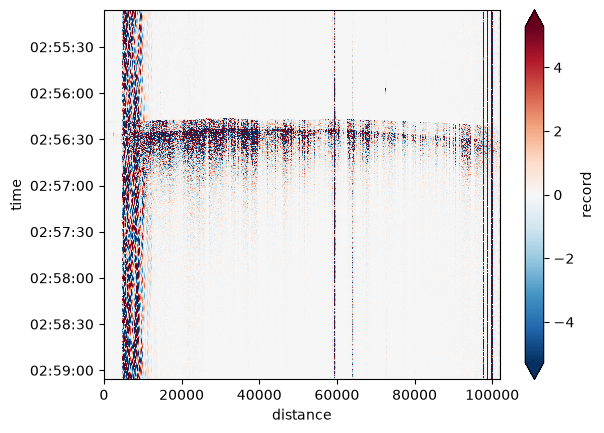

In [12]:
abyss["N"][::10, ::10].plot(robust=True, yincrease=False)

## Map

`data/topo/GMRT.nc` holds the elevation (m) of the area, as a `DataArray` with `latitude`
and `longitude` dimensions. The earthquake (EMSC) was located at 29.954°S, 71.800°W, 50 km
deep.

**Task:** draw the elevation, the coastline (the 0 m contour), the two cables and the
earthquake on the same figure.

> **Reminder:**
> ```python
> fig, ax = plt.subplots()
> topo.plot(ax=ax, cmap="Blues_r", vmin=..., vmax=...)  # an image, colors clipped to [vmin, vmax]
> ax.contour(x, y, z, levels=[...], colors="k")         # contour lines of z (2D) on the x, y grid
> ax.plot(x, y, color="red")                            # a line, or a marker with "*", "o", ...
> ax.text(x, y, "some text")                            # a label at (x, y)
> ax.set_aspect("equal")
> ```
> `plt.get_cmap("Blues_r").with_extremes(over="lightgray")` gives a colormap that draws values
> above `vmax` in gray.

📖 [`matplotlib.pyplot.contour`](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.contour.html)

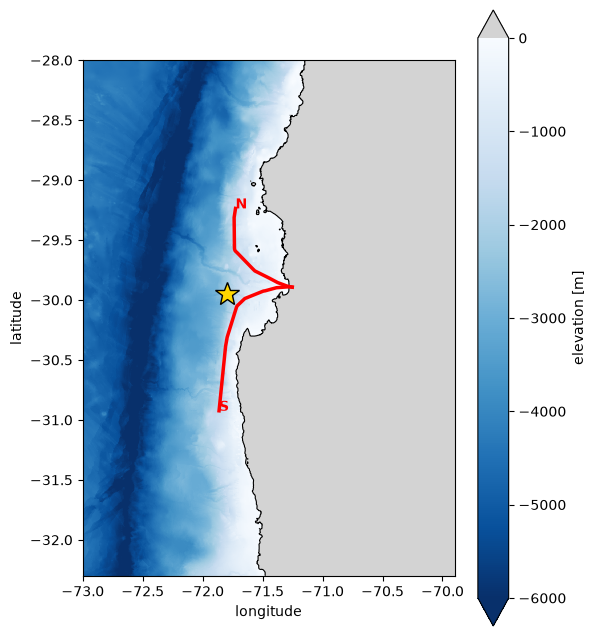

In [13]:
topo = xd.open("data/topo/GMRT.nc")
event_longitude, event_latitude = -71.800, -29.954

fig, ax = plt.subplots(figsize=(6, 8))
cmap = plt.get_cmap("Blues_r").with_extremes(over="lightgray")  # land in gray
topo.plot(ax=ax, cmap=cmap, vmin=-6000, vmax=0)
ax.contour(topo["longitude"].values, topo["latitude"].values, topo.values, levels=[0], colors="k", linewidths=0.8)
for cable in abyss:
    longitude, latitude = abyss[cable]["longitude"].values, abyss[cable]["latitude"].values
    ax.plot(longitude, latitude, color="red", linewidth=2.5)
    ax.text(longitude[-1], latitude[-1], cable, color="red", fontweight="bold")
ax.plot(event_longitude, event_latitude, "*", color="gold", markeredgecolor="k", markersize=18)
ax.set_aspect("equal")